# Aqueous NaCl activity


**Evidence: numerical verification.** Evaluate aqueous NaCl at 298.15 K and
100,000 Pa. Formula-unit molality counts NaCl per kg water; explicit species
contain one Na⁺ and one Cl⁻ per formula unit.

Use Held, Cameretti and Sadowski (2008), Tables 1–3
([paper](https://doi.org/10.1016/j.fluid.2008.06.010)), through
`held-cameretti-sadowski-2008/4`. Its `packet.toml` retains the corrected
permittivity and source conventions, including the Figiel supplement.


## Read the inputs

Use a repository checkout with the environment described in the installation
guide. The wheel alone does not contain these data. All density, association,
equilibrium and parameter-fit iterations below run in the native Engine.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from epcsaft import (
    Parameters,
    Mixture,
)
from epcsaft import equilibrium as eq

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

ROOT = next(
    folder
    for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "ARCHITECTURE.yaml").is_file()
)
PACKETS = ROOT / "data" / "packets"


def equilibrium_values(solved):
    """Keep the returned physical state and the equation residuals together."""
    assert solved.success, solved.message
    assert solved.requested_tolerance_met
    assert solved.classified_residuals
    residual = max(map(abs, solved.classified_residuals), default=0)
    assert residual <= 1e-10
    return dict(
        temperature_K=solved.temperature,
        pressure_Pa=solved.pressure,
        amounts_mol=solved.amounts,
        mole_fractions=solved.mole_fractions,
        molar_densities_mol_m3=solved.molar_densities,
        residual=residual,
        linear_solver=solved.linear_solver,
    )


## Declare an infinite-dilution reference

The solvent fractions are pure water, and ion stoichiometries are 1/1.
The native reference returns the mean ionic coefficient on the molality basis
and the osmotic coefficient. Evaluate 0.001–2 mol/kg, then solve one liquid
at 1 mol/kg on a 1 kg water basis.

At 1 mol/kg require agreement within 10⁻¹⁰ absolute with the retained baselines
0.6553145996243477 and 0.9527512738056115. Check sodium amount and charge
within 10⁻¹⁰ and classified residuals at most 10⁻¹⁰.


In [2]:
model = Mixture(
    Parameters.from_json(
        PACKETS / "held-cameretti-sadowski-2008/4/parameters/parameters.json",
        components=["water", "sodium-cation", "chloride-anion"],
    )
)
reference = model.reference(
    298.15,
    100000.0,
    solvent_fractions=(1, 0, 0),
    ions=("sodium-cation", "chloride-anion"),
    stoichiometry=(1, 1),
)
rows = [reference.activity(v) for v in (0.001, 0.01, 0.1, 0.5, 1.0, 2.0)]
feed = eq.Molalities(
    {"sodium-cation": 1, "chloride-anion": 1}, solvent=["water"], solvent_mass_kg=1
)
solved = eq.solve_equilibrium(
    model,
    eq.Problem(phases=[eq.Phase("L", kind="liquid")], T=298.15, P=100000.0, feed=feed),
)
assert abs(rows[4].mean_ionic_molality_scale - 0.6553145996243477) < 1e-10
assert abs(rows[4].osmotic_coefficient - 0.9527512738056115) < 1e-10
assert abs(solved.amounts[0] * solved.mole_fractions[1] - 1) < 1e-10
assert abs(solved.mole_fractions[1] - solved.mole_fractions[2]) < 1e-10
values = dict(
    molality_mol_kg=[0.001, 0.01, 0.1, 0.5, 1, 2],
    gamma_pm=[a.mean_ionic_molality_scale for a in rows],
    phi=[a.osmotic_coefficient for a in rows],
    liquid=equilibrium_values(solved),
)
display(
    pd.DataFrame(
        {
            "NaCl / mol kg^-1": values["molality_mol_kg"],
            "Mean ionic activity coefficient / 1": values["gamma_pm"],
            "Osmotic coefficient / 1": values["phi"],
        }
    )
)


,NaCl / mol kg^-1,Mean ionic activity coefficient / 1,Osmotic coefficient / 1
0,0.001,0.964534,0.988166
1,0.010,0.899130,0.966437
2,0.100,0.763055,0.925058
3,0.500,0.664055,0.919715
4,1.000,0.655315,0.952751
5,2.000,0.704605,1.033506


## Show the model concentration dependence

The curve joins computed model values; it contains no experimental points.


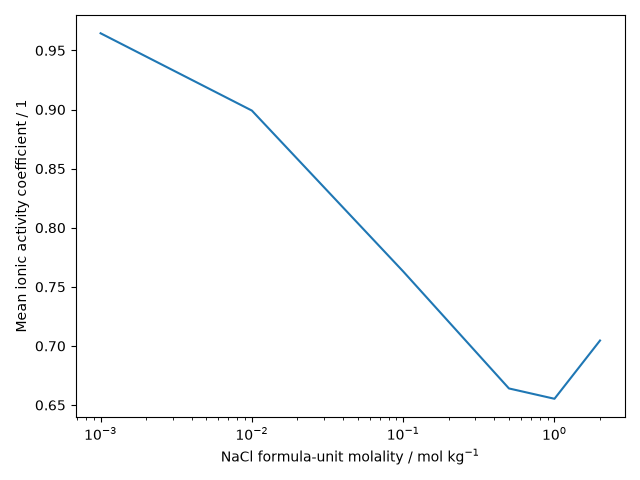

In [3]:
from io import BytesIO
from IPython.display import Image
import matplotlib.pyplot as plt

plt.plot(values["molality_mol_kg"], values["gamma_pm"])
plt.xscale("log")
plt.xlabel("NaCl formula-unit molality / mol kg$^{-1}$")
plt.ylabel("Mean ionic activity coefficient / 1")
buffer = BytesIO()
plt.tight_layout()
plt.savefig(buffer, format="png")
plt.close()
display(Image(data=buffer.getvalue()))


In [4]:
display(pd.DataFrame([values["liquid"]]).rename(columns={
            "temperature_K": "Temperature / K",
            "pressure_Pa": "Pressure / Pa",
            "amounts_mol": "Phase amounts / mol",
            "mole_fractions": "Mole fractions / 1",
            "molar_densities_mol_m3": "Phase densities / mol m^-3",
            "residual": "Maximum classified residual / 1",
            "linear_solver": "Linear solver",
        }))


,Temperature / K,Pressure / Pa,Phase amounts / mol,Mole fractions / 1,Phase densities / mol m^-3,Maximum classified residual / 1,Linear solver
0,298.15,100000.0,[57.50843506179198],"[0.9652224930507842, 0.01738875347460793, 0.01738875347460793]",[55996.043398504524],2.249255e-14,mumps


## Meaning and limits


The numerical checks establish the declared molality basis and charge closure.
They do not quantify experimental agreement or model uncertainty. Single-ion
values depend on a convention; the displayed mean coefficient is the neutral
NaCl combination. This notebook stays at 298.15 K and adds no bubble extrapolation.
